# Now with module 3

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_1.h5 ...
Loaded 97,773 events over 188.65 seconds.
Total DAQ Trigger Rate: 518.3 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 226.0 (±25.0)    | 503.0 (±25.0)    | 0.00    % | 0.00    % | 4,708       | 25.0       | OK (Cosmic) 
1     |  2, 3    | 529.0 (±25.0)    | 612.0 (±25.0)    | 0.00    % | 0.00    % | 1,399       | 7.4        | OK (Cosmic) 
2     |  4, 5    | 214.0 (±19.3)    | 348.0 (±25.0)    | 0.00    % | 0.00    % | 4,413       | 23.4       | OK (Cosmic) 
3     |  6, 7    | 354.0 (±25.0)    | 155.0 (±25.0)    | 0.00    % | 0.00    % | 4           | 0.0        | DEAF / OFF  
4     |  8, 9    | 233.0 (±25.0)    | 210.0 (±25.0)    | 0.00    % | 0.00    % | 6,913       | 36.6       | OK (Cosmic) 
5     | 10, 11   | 174.0 (±25.0)    | 299.0 (±25.0)    | 0.00    % | 0.00    % | 11,351      | 60.2       | S

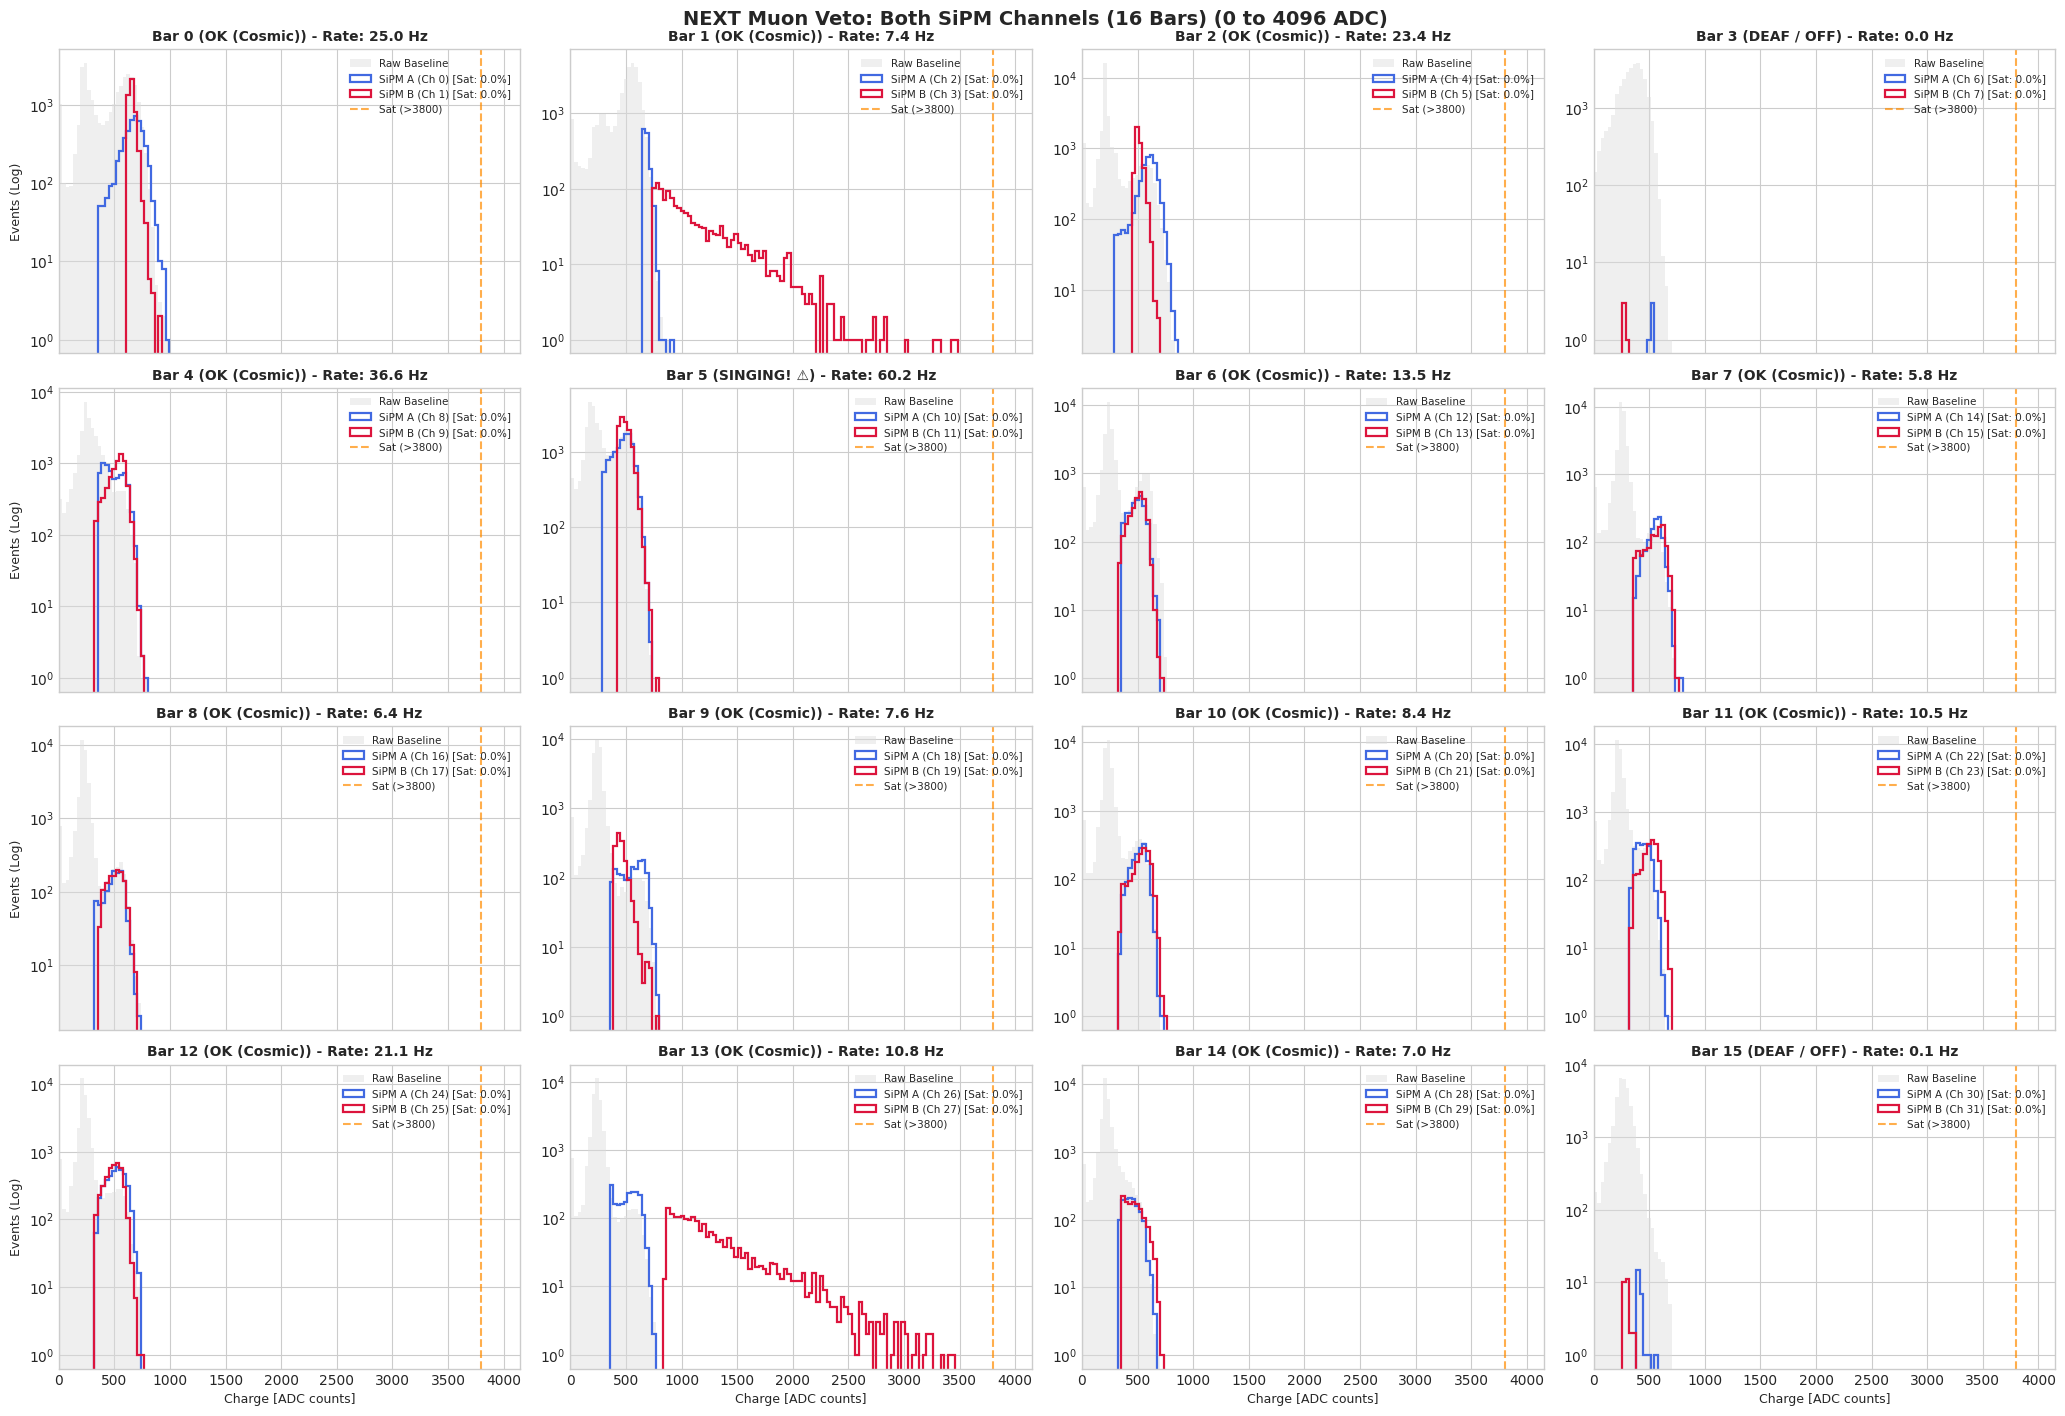

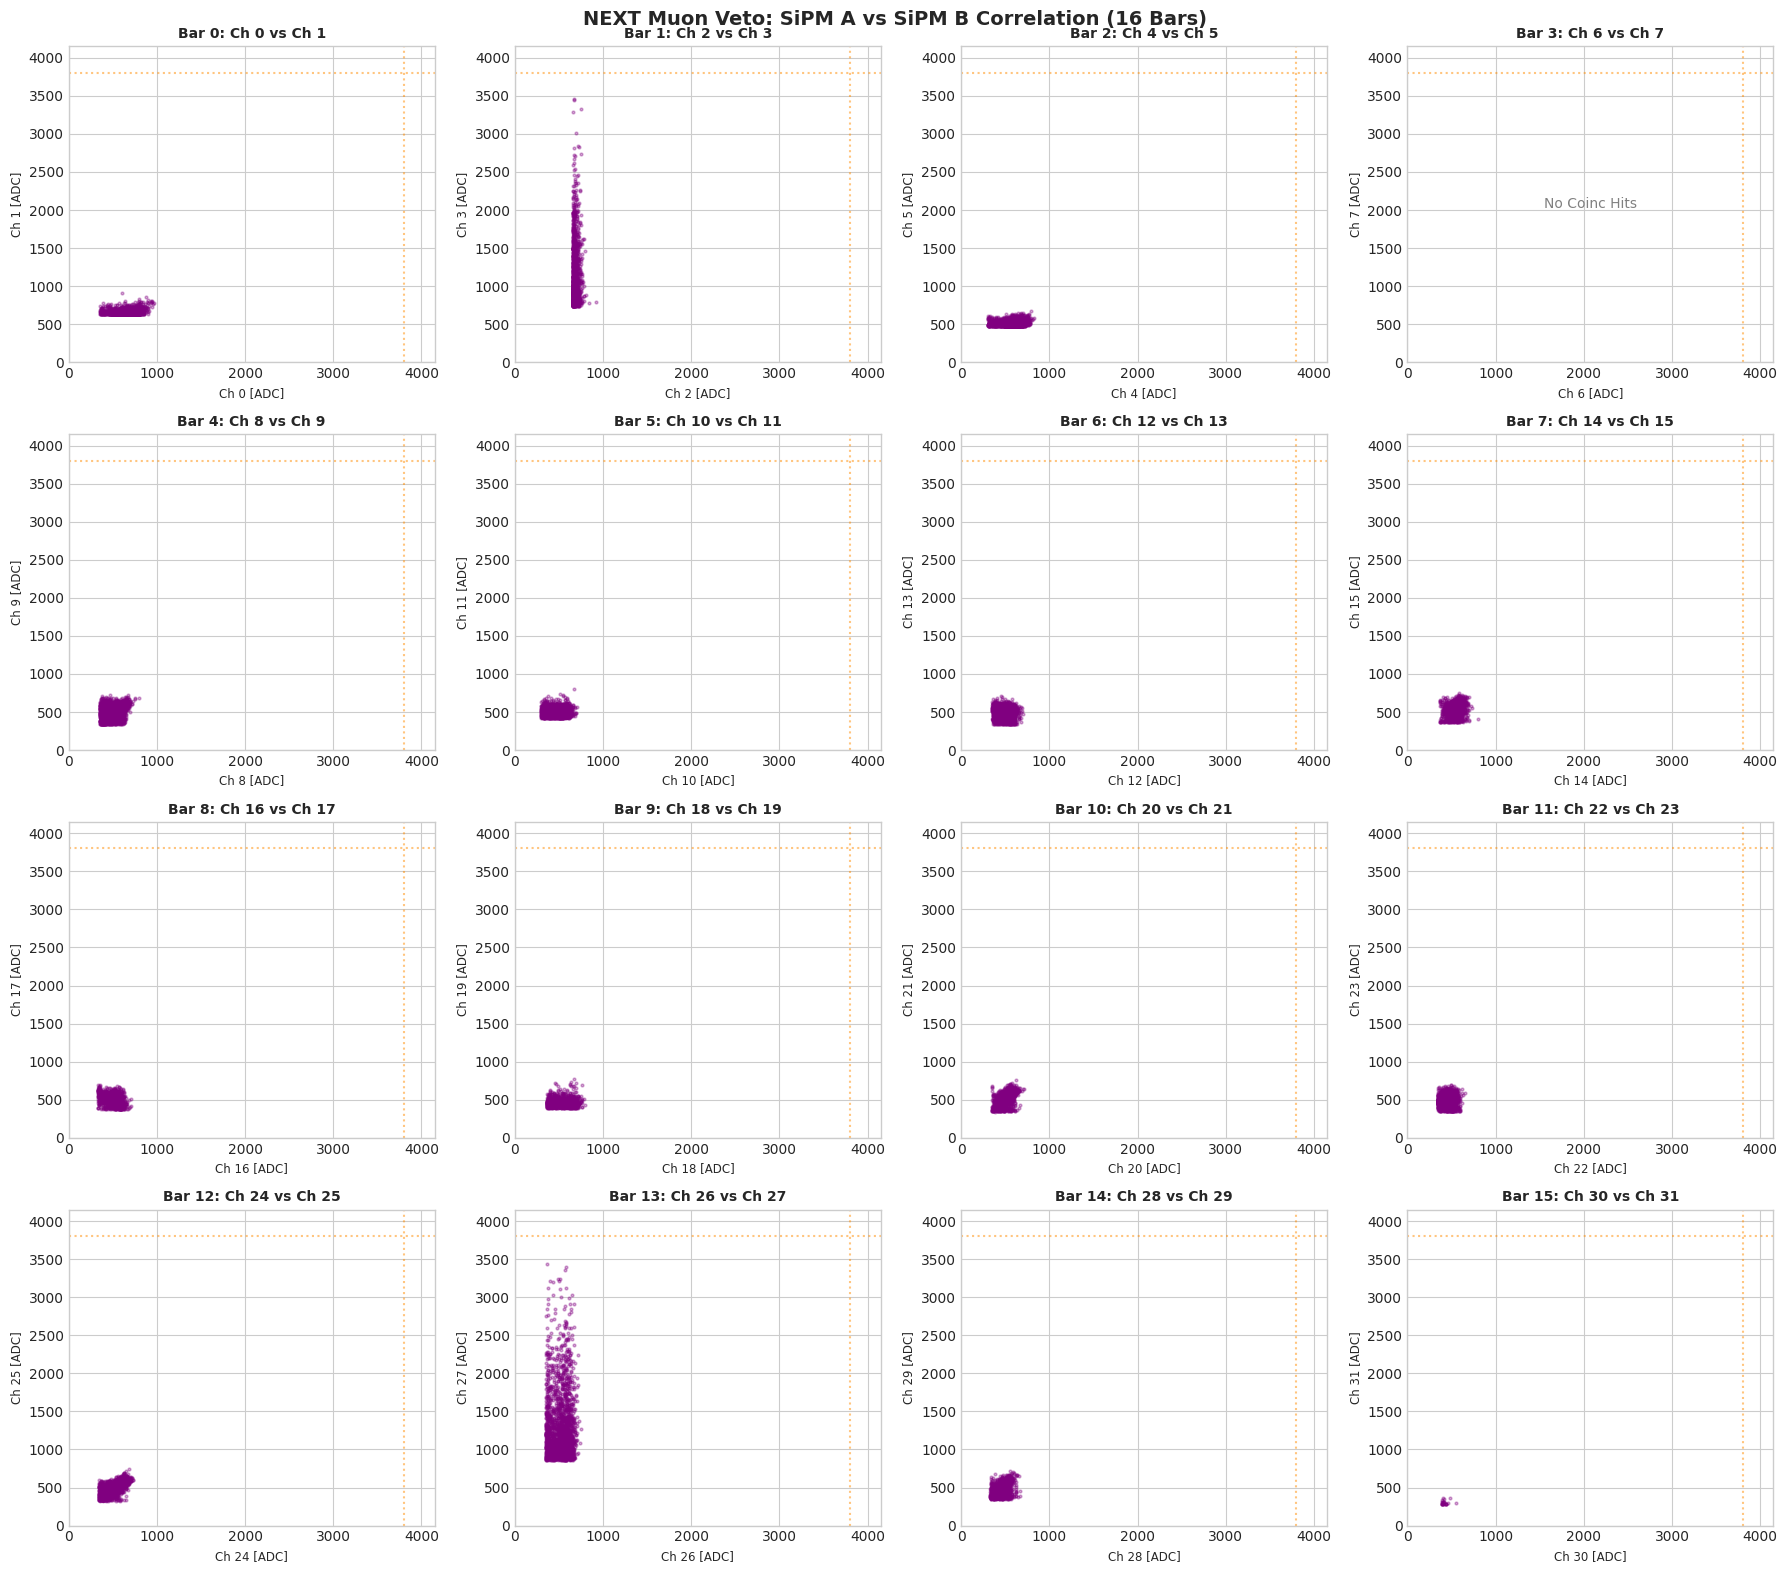

In [7]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_1.h5"

# All 16 bars mapped to the 32 CAEN channels
BAR_MAP = {
    0:  (0, 1),
    1:  (2, 3),
    2:  (4, 5),
    3:  (6, 7),
    4:  (8, 9),
    5:  (10, 11),
    6:  (12, 13),
    7:  (14, 15),
    8:  (16, 17),
    9:  (18, 19),
    10: (20, 21),
    11: (22, 23),
    12: (24, 25),
    13: (26, 27),
    14: (28, 29),
    15: (30, 31)
}

SATURATION_ADC = 3800  # ADC count threshold for saturation

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION (All 32 Channels)
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# DYNAMIC GRID CALCULATION
# ==============================================================================
n_bars = len(BAR_MAP)
n_cols = 4 if n_bars > 9 else 3
n_rows = int(np.ceil(n_bars / n_cols))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# PLOT 1: BOTH SiPMs OVERLAID PER BAR (FULL RANGE 0-4096)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 3.6 * n_rows), sharex=True)
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    # Subsampled raw baseline for comparison
    raw_sub = q_a if len(q_a) <= 30000 else np.random.choice(q_a, 30000, replace=False)
    ax.hist(raw_sub, bins=128, range=(0, 4096), color='gainsboro', label='Raw Baseline', alpha=0.45)
    
    # Overlay both SiPMs
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=128, range=(0, 4096), color='royalblue', 
                histtype='step', linewidth=1.6, label=f'SiPM A (Ch {ch_a}) [Sat: {bar_stats[bar_id]["sat_a_pct"]:.1f}%]')
        ax.hist(q_b[coinc_mask], bins=128, range=(0, 4096), color='crimson', 
                histtype='step', linewidth=1.6, label=f'SiPM B (Ch {ch_b}) [Sat: {bar_stats[bar_id]["sat_b_pct"]:.1f}%]')
        
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7, label='Sat (>3800)')
    
    ax.set_title(f"Bar {bar_id} ({bar_stats[bar_id]['status']}) - Rate: {bar_stats[bar_id]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, 4150)
    ax.legend(fontsize=7.5, loc='upper right', framealpha=0.9)
    
    # Add axis labels to bottom and left borders
    if idx >= (n_rows - 1) * n_cols or (idx + n_cols) >= n_bars:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if idx % n_cols == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

# Hide any extra empty subplot boxes if n_bars is not a multiple of n_cols
for ax in axes[n_bars:]:
    ax.axis('off')

plt.suptitle(f"NEXT Muon Veto: Both SiPM Channels ({n_bars} Bars) (0 to 4096 ADC)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_both_sipms_dynamic.png", dpi=200)
print("[+] Saved: veto_both_sipms_dynamic.png")

# ==============================================================================
# PLOT 2: FULL-RANGE 2D CORRELATION (0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.0 * n_rows))
axes = axes.flatten()

for idx, bar_id in enumerate(BAR_MAP.keys()):
    ax = axes[idx]
    ch_a = bar_stats[bar_id]['ch_a']
    ch_b = bar_stats[bar_id]['ch_b']
    q_a = bar_stats[bar_id]['q_a']
    q_b = bar_stats[bar_id]['q_b']
    coinc_mask = bar_stats[bar_id]['mask']
    
    if np.sum(coinc_mask) > 5:
        sub_indices = np.where(coinc_mask)[0]
        if len(sub_indices) > 3000:
            sub_indices = np.random.choice(sub_indices, 3000, replace=False)
        ax.scatter(q_a[sub_indices], q_b[sub_indices], color='purple', s=4, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coinc Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {bar_id}: Ch {ch_a} vs Ch {ch_b}", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=8.5)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=8.5)

# Hide any extra empty subplots
for ax in axes[n_bars:]:
    ax.axis('off')

plt.suptitle(f"NEXT Muon Veto: SiPM A vs SiPM B Correlation ({n_bars} Bars)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_sipm_correlations_dynamic.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_dynamic.png")
print("\nDone! Now you can analyze any number of bars automatically.")

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_2.h5 ...
Loaded 16,931 events over 154.55 seconds.
Total DAQ Trigger Rate: 109.6 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 222.0 (±25.0)    | 254.0 (±25.0)    | 0.00    % | 0.00    % | 1,144       | 7.4        | OK (Cosmic) 
1     |  2, 3    | 279.0 (±25.0)    | 202.0 (±25.0)    | 0.00    % | 0.03    % | 3,544       | 22.9       | OK (Cosmic) 
2     |  4, 5    | 216.0 (±25.0)    | 240.0 (±25.0)    | 0.00    % | 0.00    % | 850         | 5.5        | OK (Cosmic) 
3     |  6, 7    | 258.0 (±25.0)    | 201.0 (±25.0)    | 0.00    % | 0.00    % | 0           | 0.0        | DEAF / OFF  
4     |  8, 9    | 237.0 (±25.0)    | 209.0 (±25.0)    | 0.00    % | 0.00    % | 742         | 4.8        | OK (Cosmic) 
5     | 10, 11   | 229.0 (±25.0)    | 225.0 (±25.0)    | 0.00    % | 0.00    % | 1,307       | 8.5        | O

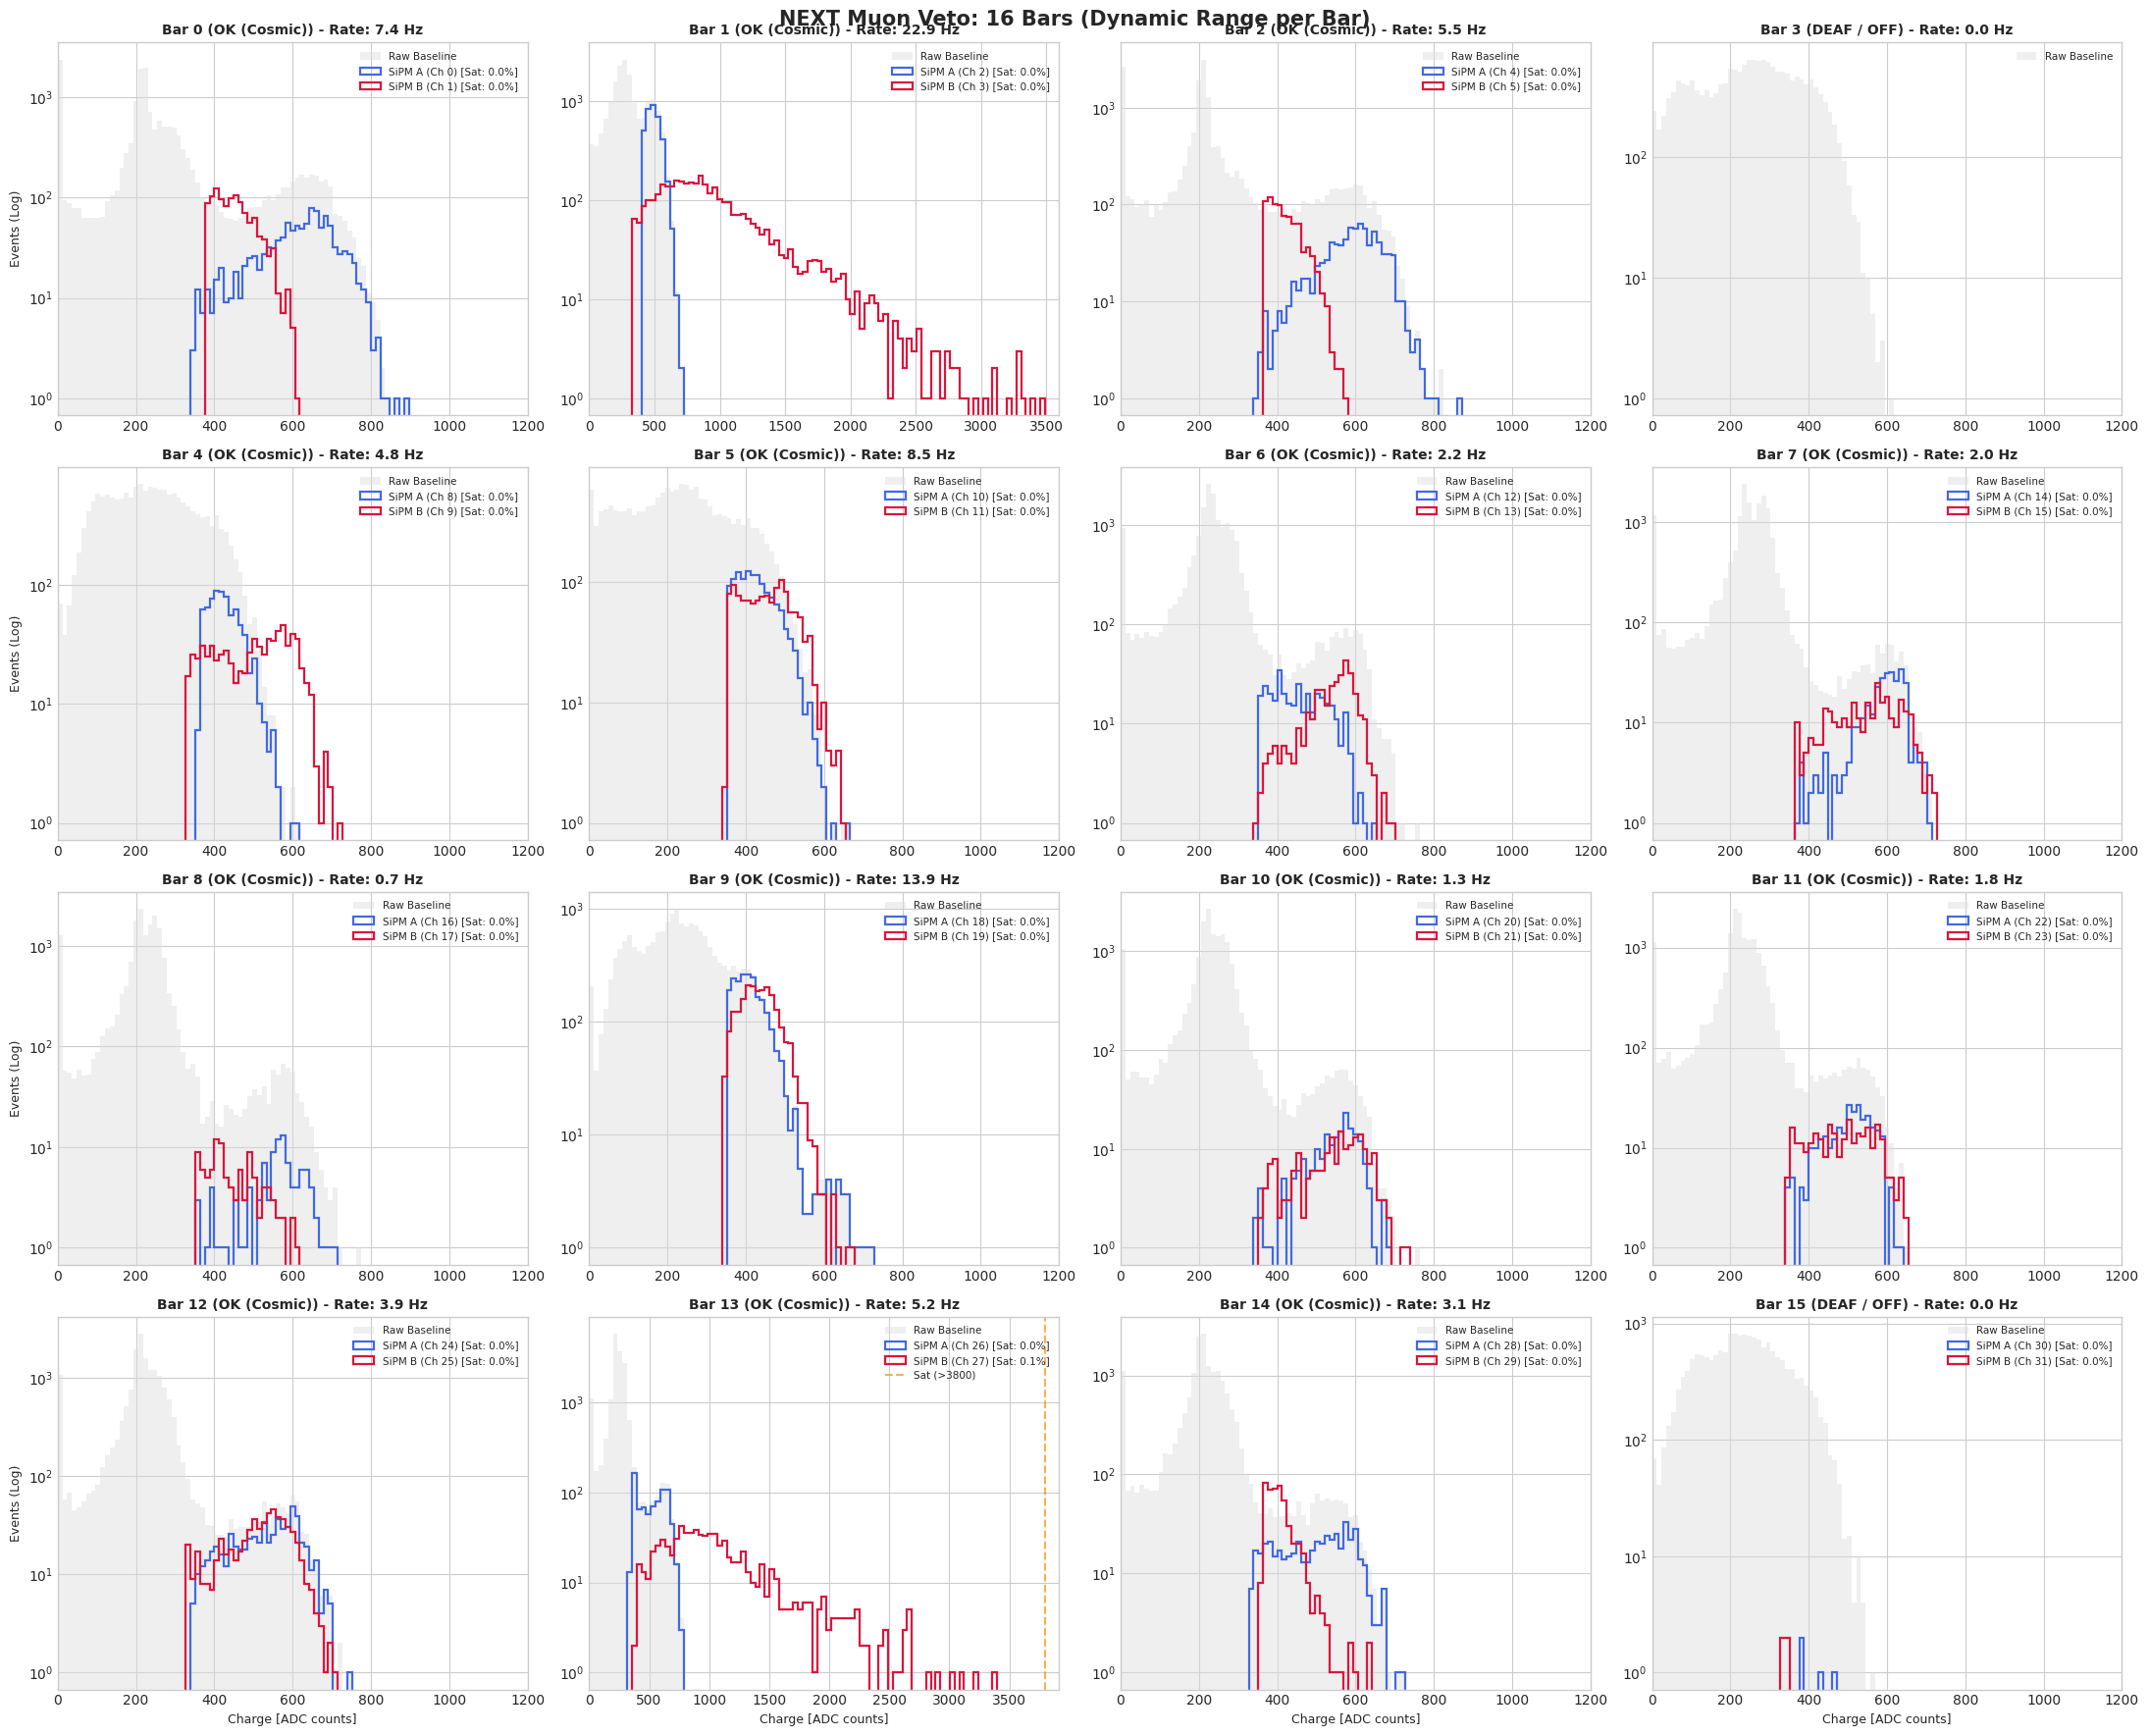

In [8]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_2.h5"  # <-- Replace with your file name

# 16-Bar Mapping: Bar 0 to 15 (Channels 0 to 31)
BAR_MAP = {i: (2 * i, 2 * i + 1) for i in range(16)}

SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}

print("=" * 126)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 126)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 0.5:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 126 + "\n")

# ==============================================================================
# PLOTTING: 16 BARS (4x4) WITH DYNAMIC X-AXIS RANGE
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(4, 4, figsize=(22, 18))
axes = axes.flatten()

for b in range(16):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Calculate DYNAMIC X-AXIS LIMIT:
    # Look at 99.8th percentile of coincident data so low-rate bars aren't squished!
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        x_limit = 1200
        
    bins = np.linspace(0, x_limit, 100)
    
    # Subsampled raw baseline
    raw_sub = q_a if len(q_a) <= 20000 else np.random.choice(q_a, 20000, replace=False)
    ax.hist(raw_sub, bins=bins, color='gainsboro', label='Raw Baseline', alpha=0.45)
    
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'SiPM A (Ch {ch_a}) [Sat: {bar_stats[b]["sat_a_pct"]:.1f}%]')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'SiPM B (Ch {ch_b}) [Sat: {bar_stats[b]["sat_b_pct"]:.1f}%]')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7, label='Sat (>3800)')
        
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7.5, loc='upper right', framealpha=0.9)
    
    if b >= 12:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto: 16 Bars (Dynamic Range per Bar)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_16bars_dynamic_range.png", dpi=200)
print("[+] Saved: veto_16bars_dynamic_range.png")

In [9]:
# Quick check of Channel 7 and Channel 31 standalone:
print("Ch 6 max ADC:", np.max(charges[:, 6]), "| Ch 7 max ADC:", np.max(charges[:, 7]))
print("Ch 30 max ADC:", np.max(charges[:, 30]), "| Ch 31 max ADC:", np.max(charges[:, 31]))

Ch 6 max ADC: 609 | Ch 7 max ADC: 422
Ch 30 max ADC: 561 | Ch 31 max ADC: 432


In [ ]:
# Next version

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_2.h5 ...
Loaded 16,931 events over 154.55 seconds.
Total DAQ Trigger Rate: 109.6 Hz

--- STANDALONE MAXIMUM ADC CHECK (DIAGNOSTIC) ---
Channel  6: Max ADC = 609   | 99.9th Percentile = 548.2
Channel  7: Max ADC = 422   | 99.9th Percentile = 379.0
Channel 30: Max ADC = 561   | 99.9th Percentile = 513.0
Channel 31: Max ADC = 432   | 99.9th Percentile = 396.0
-------------------------------------------------

[+] Saved: veto_16bars_dual_backgrounds.png


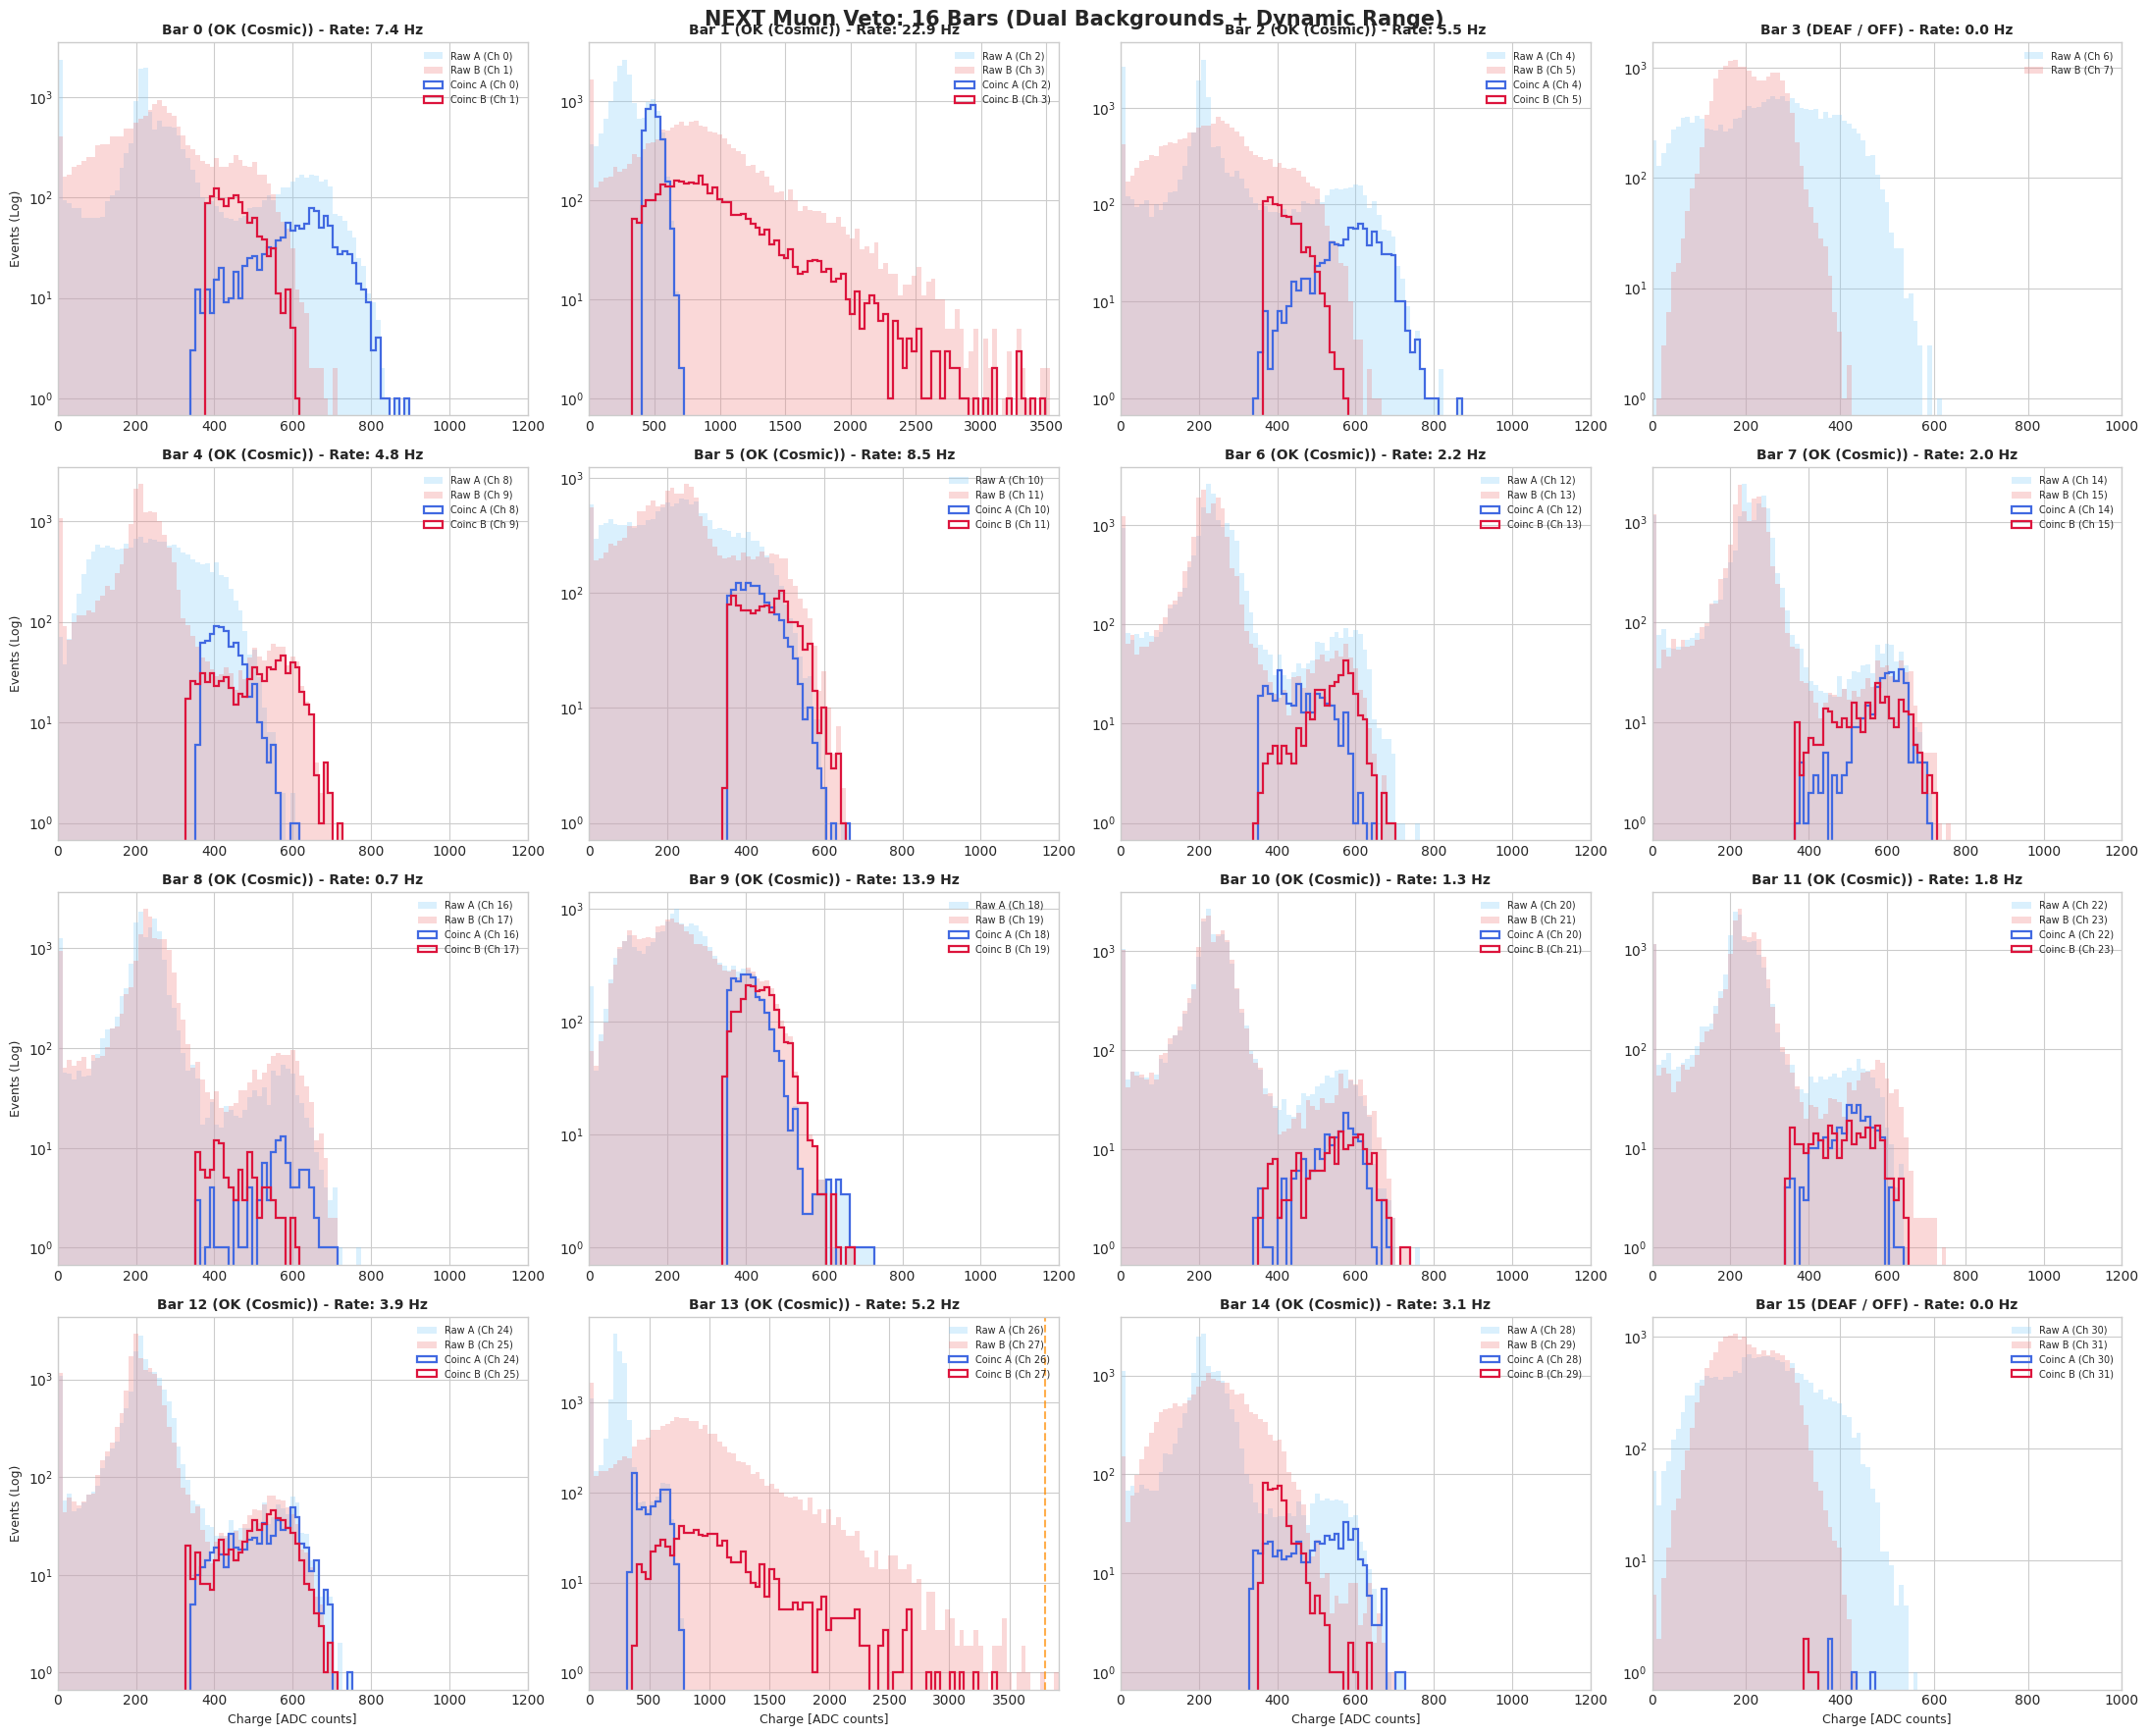

In [10]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_2.h5"  # <-- Replace with your file name
BAR_MAP = {i: (2 * i, 2 * i + 1) for i in range(16)}
SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# Check standalone max ADC for dead bar diagnostics
print("--- STANDALONE MAXIMUM ADC CHECK (DIAGNOSTIC) ---")
for ch in [6, 7, 30, 31]:
    max_val = np.max(charges[:, ch])
    q99 = np.percentile(charges[:, ch], 99.9)
    print(f"Channel {ch:>2}: Max ADC = {max_val:<5} | 99.9th Percentile = {q99:<5.1f}")
print("-------------------------------------------------\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH
# ==============================================================================
bar_stats = {}

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 0.5:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }

# ==============================================================================
# PLOTTING: DUAL RAW BACKGROUNDS + DYNAMIC X-AXIS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(4, 4, figsize=(22, 18))
axes = axes.flatten()

for b in range(16):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Dynamic x-axis based on both channels
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        # If no coincidences, base limit on raw activity
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    sub_size = min(len(q_a), 20000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    
    # DUAL BACKGROUNDS: Show Raw A and Raw B separately!
    ax.hist(q_a[sub_idx], bins=bins, color='lightskyblue', alpha=0.3, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, color='lightcoral', alpha=0.3, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 12:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto: 16 Bars (Dual Backgrounds + Dynamic Range)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_16bars_dual_backgrounds.png", dpi=200)
print("[+] Saved: veto_16bars_dual_backgrounds.png")

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_3.h5 ...
Loaded 22,619 events over 230.00 seconds.
Total DAQ Trigger Rate: 98.3 Hz

--- STANDALONE MAXIMUM ADC CHECK (DIAGNOSTIC) ---
Channel  6: Max ADC = 853   | 99.9th Percentile = 560.1
Channel  7: Max ADC = 434   | 99.9th Percentile = 379.8
Channel 30: Max ADC = 1013  | 99.9th Percentile = 526.8
Channel 31: Max ADC = 637   | 99.9th Percentile = 434.5
-------------------------------------------------

[+] Saved: veto_16bars_dual_backgrounds.png


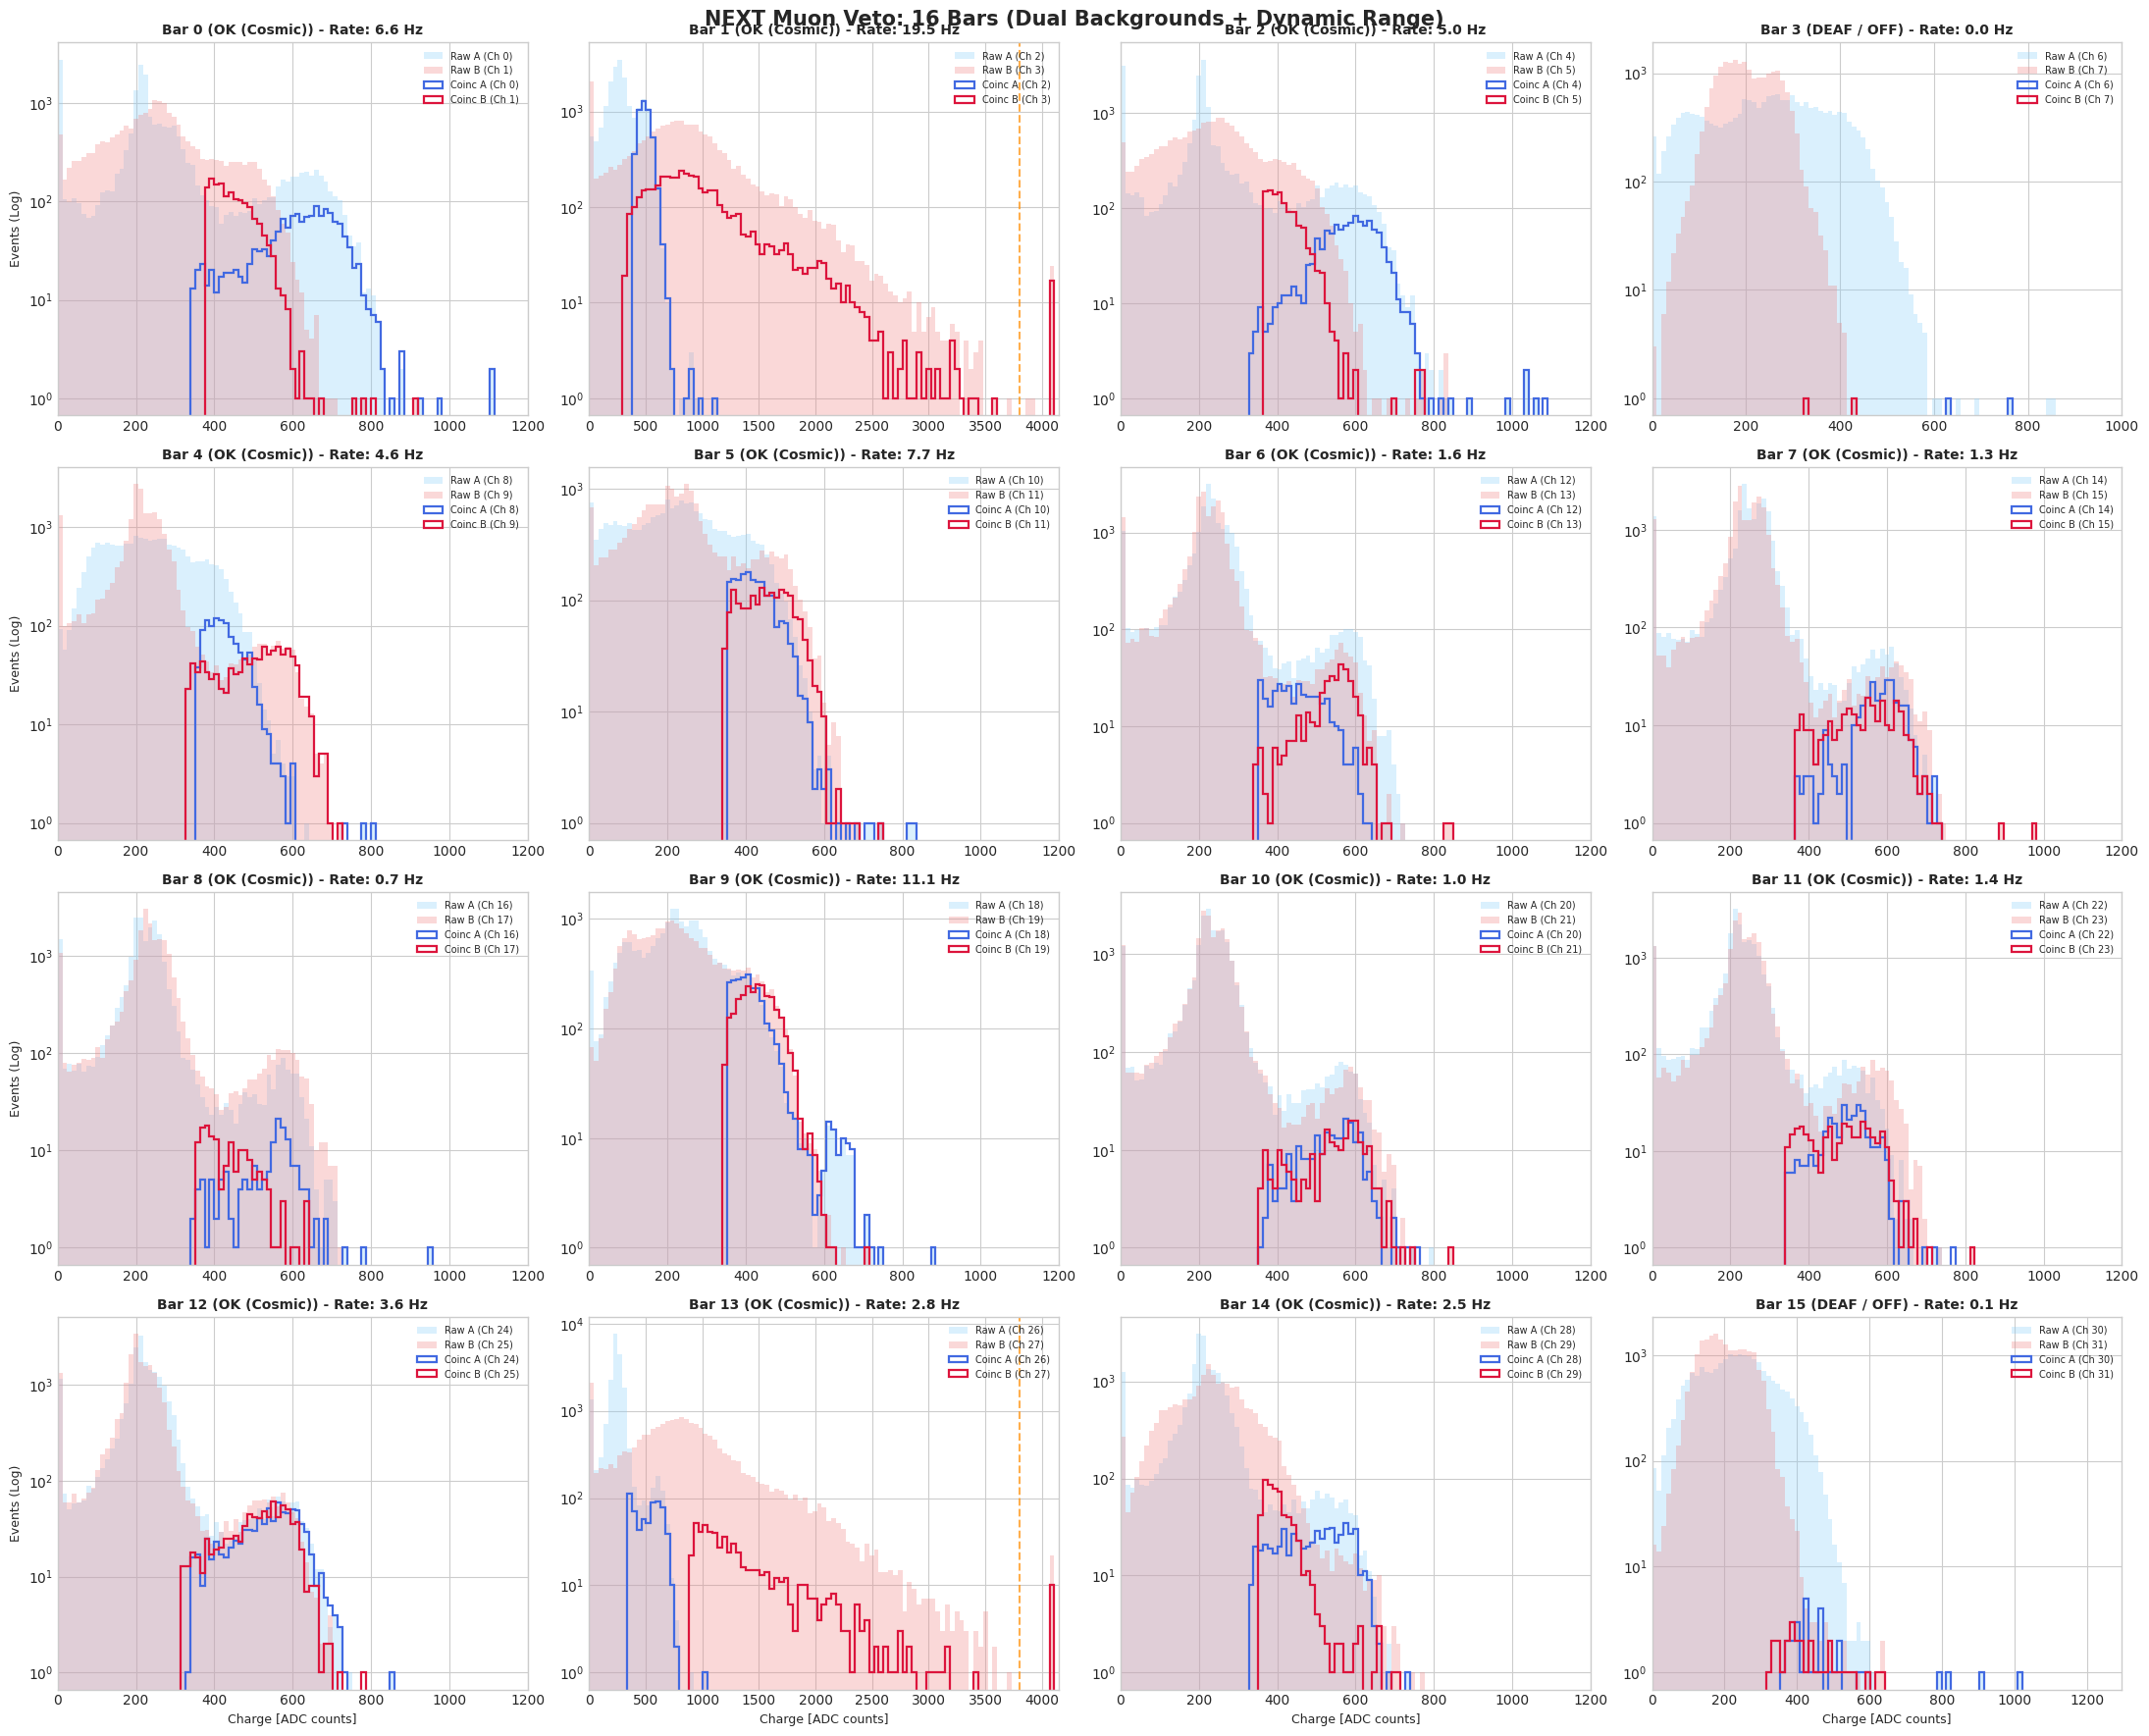

In [11]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_3.h5"  # <-- Replace with your file name
BAR_MAP = {i: (2 * i, 2 * i + 1) for i in range(16)}
SATURATION_ADC = 3800

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# Check standalone max ADC for dead bar diagnostics
print("--- STANDALONE MAXIMUM ADC CHECK (DIAGNOSTIC) ---")
for ch in [6, 7, 30, 31]:
    max_val = np.max(charges[:, ch])
    q99 = np.percentile(charges[:, ch], 99.9)
    print(f"Channel {ch:>2}: Max ADC = {max_val:<5} | 99.9th Percentile = {q99:<5.1f}")
print("-------------------------------------------------\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH
# ==============================================================================
bar_stats = {}

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 0.5:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }

# ==============================================================================
# PLOTTING: DUAL RAW BACKGROUNDS + DYNAMIC X-AXIS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(4, 4, figsize=(22, 18))
axes = axes.flatten()

for b in range(16):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Dynamic x-axis based on both channels
    if np.sum(coinc_mask) > 10:
        max_seen = max(np.percentile(q_a[coinc_mask], 99.5), np.percentile(q_b[coinc_mask], 99.5))
        x_limit = min(max(max_seen * 1.3, 1200), 4150)
    else:
        # If no coincidences, base limit on raw activity
        max_raw = max(np.percentile(q_a, 99.5), np.percentile(q_b, 99.5))
        x_limit = min(max(max_raw * 1.3, 1000), 4150)
        
    bins = np.linspace(0, x_limit, 100)
    sub_size = min(len(q_a), 20000)
    sub_idx = np.random.choice(len(q_a), sub_size, replace=False)
    
    # DUAL BACKGROUNDS: Show Raw A and Raw B separately!
    ax.hist(q_a[sub_idx], bins=bins, color='lightskyblue', alpha=0.3, label=f'Raw A (Ch {ch_a})')
    ax.hist(q_b[sub_idx], bins=bins, color='lightcoral', alpha=0.3, label=f'Raw B (Ch {ch_b})')
    
    # Coincidence signals
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=bins, color='royalblue', 
                histtype='step', linewidth=1.6, label=f'Coinc A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=bins, color='crimson', 
                histtype='step', linewidth=1.6, label=f'Coinc B (Ch {ch_b})')
        
    if x_limit >= 3800:
        ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7)
        
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, x_limit)
    ax.legend(fontsize=7, loc='upper right', framealpha=0.9)
    
    if b >= 12:
        ax.set_xlabel("Charge [ADC counts]", fontsize=9)
    if b % 4 == 0:
        ax.set_ylabel("Events (Log)", fontsize=9)

plt.suptitle("NEXT Muon Veto: 16 Bars (Dual Backgrounds + Dynamic Range)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_16bars_dual_backgrounds.png", dpi=200)
print("[+] Saved: veto_16bars_dual_backgrounds.png")

# next try

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_M3_4.h5 ...
Loaded 10,956 events over 94.95 seconds.
Total DAQ Trigger Rate: 115.4 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 216.0 (±25.0)    | 251.0 (±25.0)    | 0.00    % | 0.00    % | 745         | 7.8        | OK (Cosmic) 
1     |  2, 3    | 274.0 (±25.0)    | 722.0 (±25.0)    | 0.00    % | 0.00    % | 1,006       | 10.6       | OK (Cosmic) 
2     |  4, 5    | 213.0 (±25.0)    | 235.0 (±25.0)    | 0.00    % | 0.00    % | 554         | 5.8        | OK (Cosmic) 
3     |  6, 7    | 255.0 (±25.0)    | 195.0 (±25.0)    | 0.00    % | 0.00    % | 1           | 0.0        | DEAF / OFF  
4     |  8, 9    | 234.0 (±25.0)    | 208.0 (±25.0)    | 0.00    % | 0.00    % | 472         | 5.0        | OK (Cosmic) 
5     | 10, 11   | 228.0 (±25.0)    | 222.0 (±25.0)    | 0.00    % | 0.00    % | 841         | 8.9        | OK

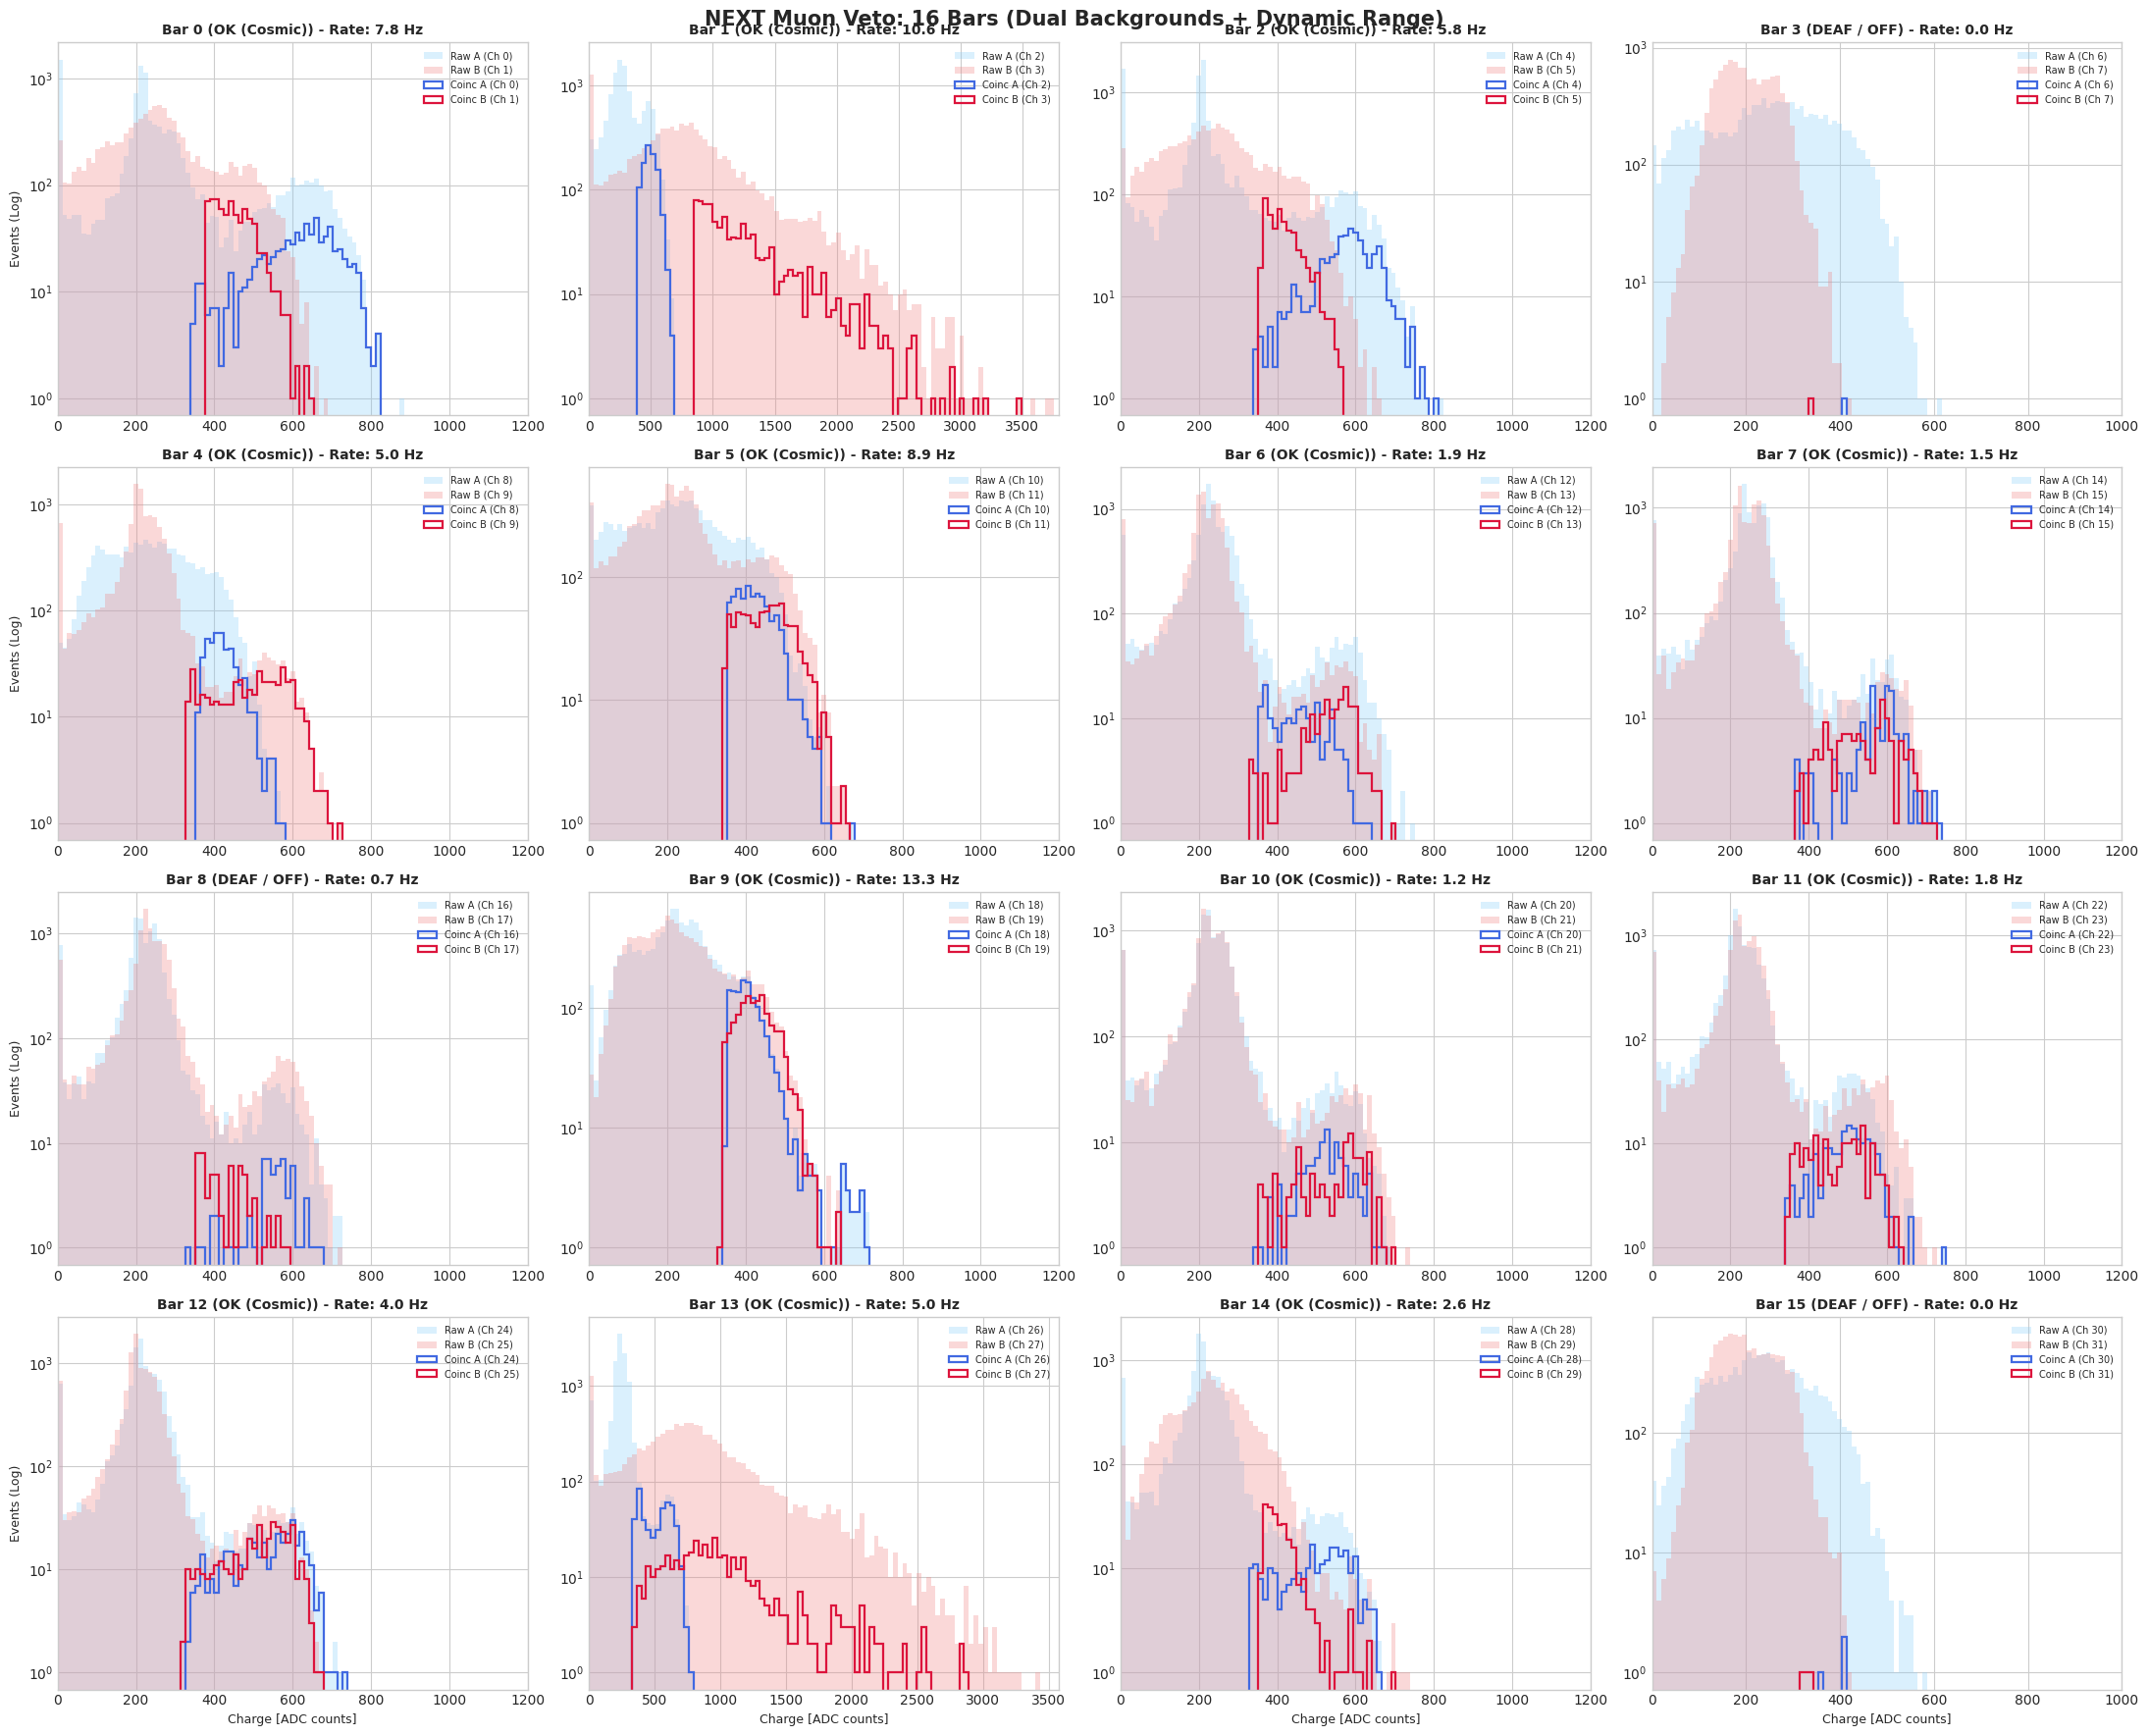

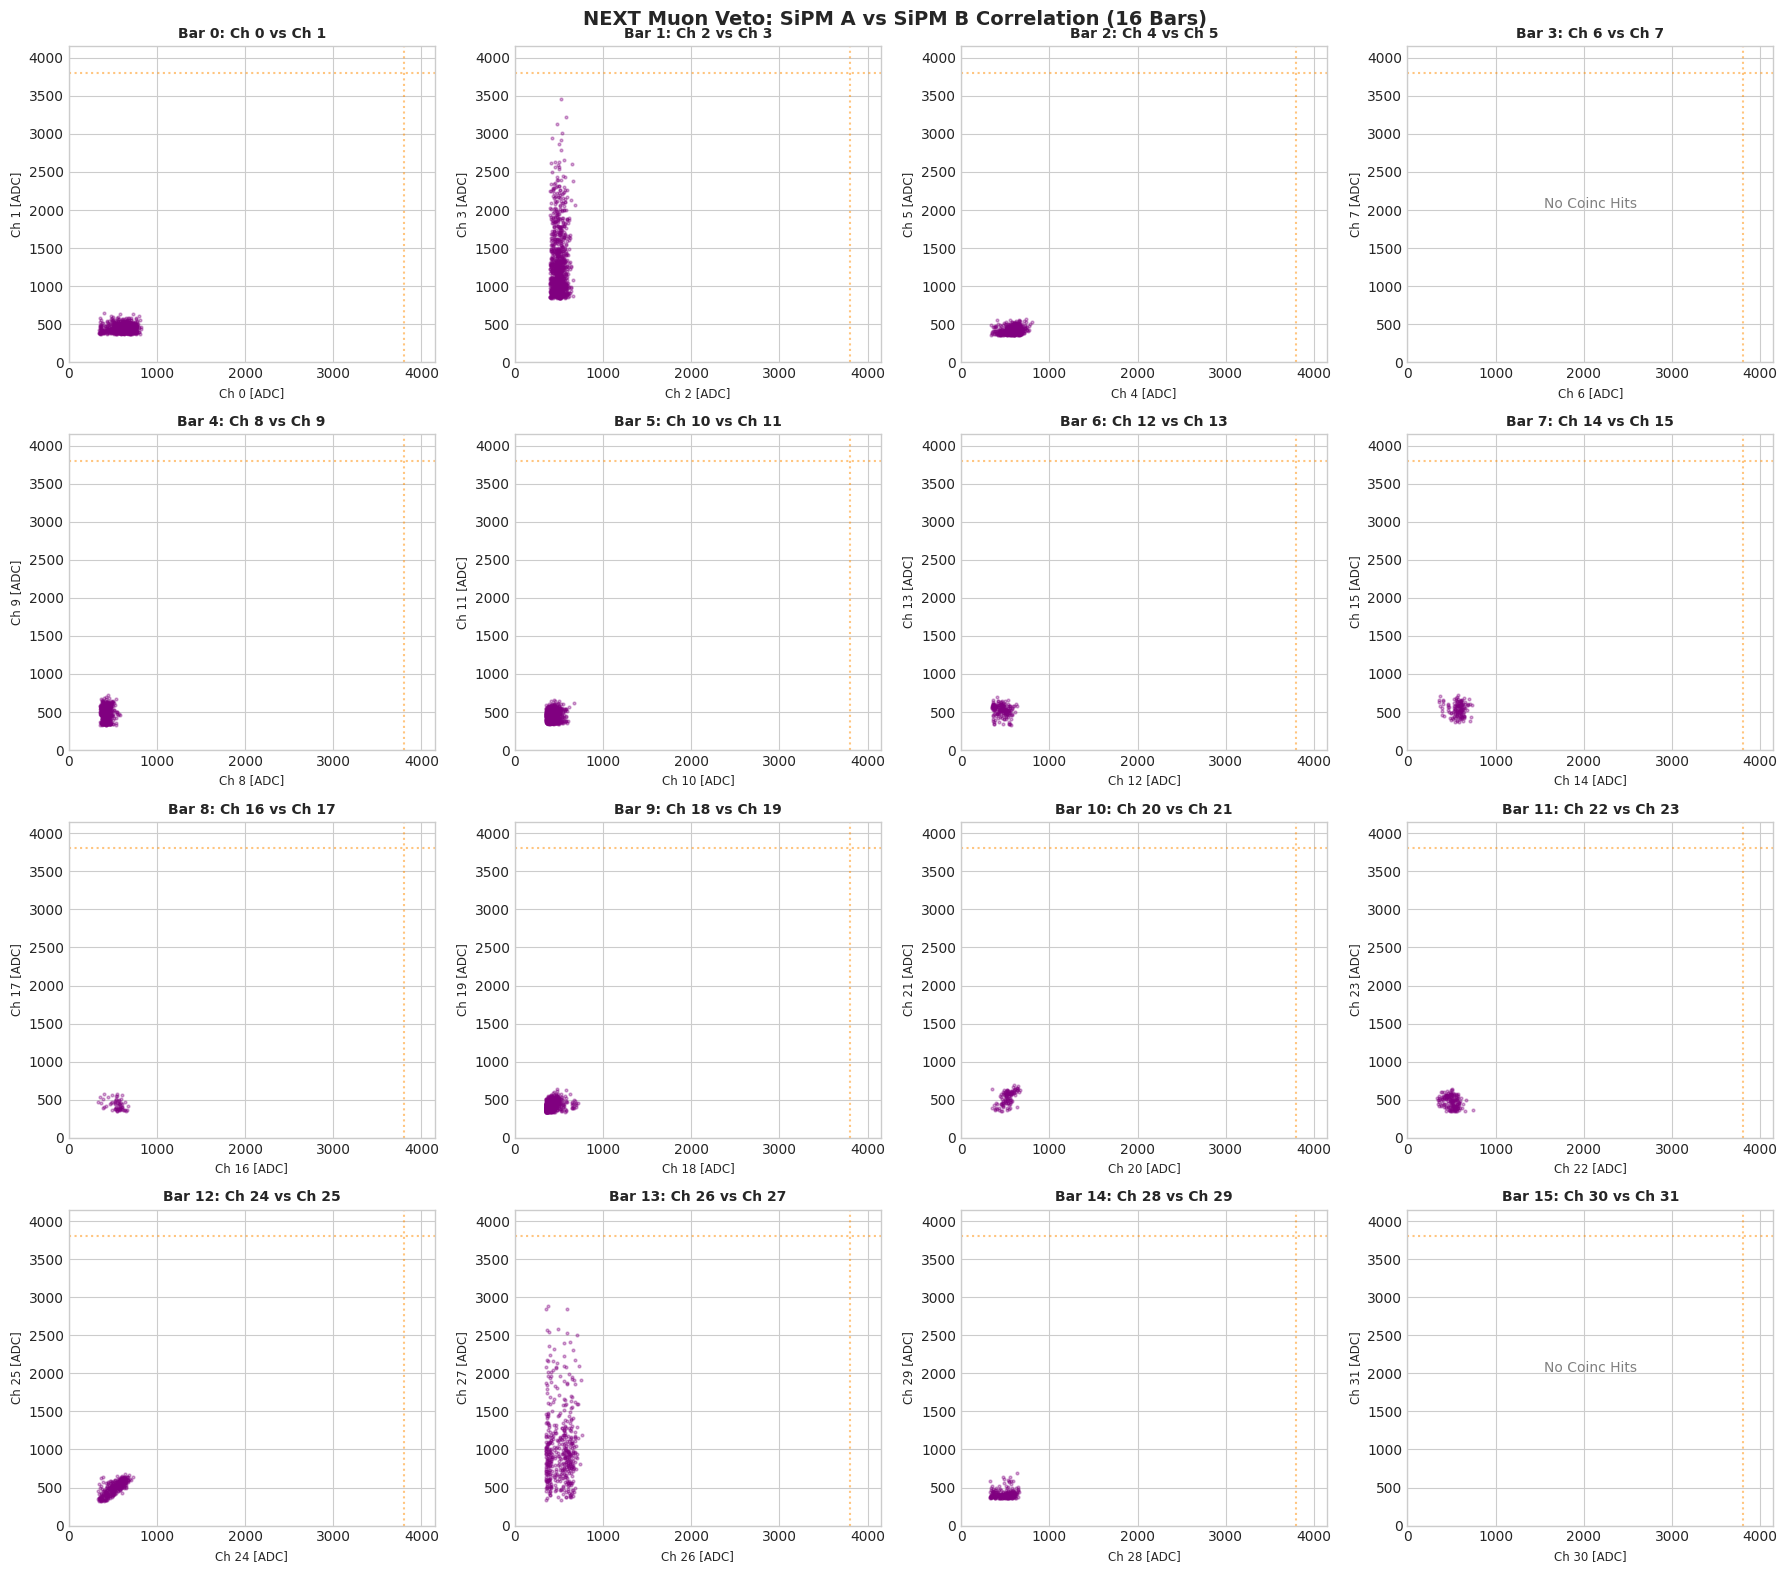